# Asset × contract batching on CPU and CUDA

`MultiAssetBatch` prices a rectangular portfolio of **independent assets**, each
with several option contracts. It does not price a correlated basket payoff.
Here each asset has its own spot, rate, volatility parameter and log-spot mesh;
each row has three one-year European calls. Valuation is 2025-01-01 and expiry
is 2026-01-01 (Actual/365 Fixed). Continuously compounded risk-free rates run
from 2% to 3.5%; the dividend yield is 0.5% for every asset.

Compatible assets share mesh shapes, coefficient times, expiry horizon, scheme,
step count, event schedules and contract count. Their coordinates, coefficients,
curves and strikes may differ. Incompatible configurations form separate groups
without silently changing numerical settings. All arrays use `float64`.

In [1]:
import math
import statistics
import time
import torch
import matplotlib.pyplot as plt
from quantlibtorch import MultiAssetBatch, state_grid

torch.set_num_threads(1)
DTYPE = torch.float64
spots = [90., 100., 110., 120.]
times = [0., .5, 1.]
configs = []
for i, spot in enumerate(spots):
    axes = [torch.linspace(math.log(.4*spot), math.log(2.5*spot), 21, dtype=DTYPE).tolist(),
            torch.linspace(-1., 1., 9, dtype=DTYPE).tolist()]
    configs.append(dict(axes=axes, times=times, strikes=[.9*spot, spot, 1.1*spot],
                        rate=.02+.005*i, dividend_yield=.005, time_steps=12))

state_tensors = {}
def make_plan(device):
    # Sample geometry once at setup, and keep it resident during training.
    resident_states = torch.stack([state_grid(c["axes"]) for c in configs]).to(device)
    state_tensors[str(resident_states.device)] = resident_states
    return MultiAssetBatch(configs, device=device, checkpoint_steps=4)

def fields(parameters, initial_spots):
    # Shapes: [assets, coefficient times, nodes, latent directions/noise directions].
    device = parameters.device
    states = state_tensors[str(device)]
    y = states[:, None, :, 1].expand(-1, len(times), -1)
    vol = .12+.18*torch.sigmoid(parameters[:, None, None]+.3*y)
    latent_vol = torch.full_like(vol, .15)
    zero = torch.zeros_like(vol)
    drift = (-.1*y)[..., None]
    loading = torch.stack((torch.stack((vol, zero), -1),
                           torch.stack((zero, latent_vol), -1)), -2)
    initial = torch.stack((initial_spots.log(), torch.full_like(initial_spots, .05)), -1)
    return drift, loading, initial

cpu_plan = make_plan("cpu")
print("Compatible asset groups:", cpu_plan.groups)
parameters = torch.tensor([-.3, -.1, .1, .3], dtype=DTYPE, requires_grad=True)
initial_spots = torch.tensor(spots, dtype=DTYPE, requires_grad=True)
sample_fields = fields(parameters, initial_spots)
print("Drift, diffusion and initial-state shapes:", [tuple(t.shape) for t in sample_fields])
cpu_prices = cpu_plan.price(*sample_fields, mode="adjoint")
parameter_grad, deltas = torch.autograd.grad(cpu_prices.sum(), (parameters, initial_spots))
assert cpu_prices.shape == (len(spots), 3)
assert torch.all(parameter_grad > 0) and torch.all(deltas > 0)
print("Price matrix [assets, contracts]:")
print(cpu_prices.detach())
print("Sum-of-contract parameter sensitivities:", parameter_grad.tolist())
print("Sum-of-contract spot Deltas:", deltas.tolist())

Compatible asset groups: ((0, 1, 2, 3),)
Drift, diffusion and initial-state shapes: [(4, 3, 189, 1), (4, 3, 189, 2, 2), (4, 2)]


Price matrix [assets, contracts]:
tensor([[12.9402,  7.6862,  4.2126],
        [14.9570,  9.1316,  5.1897],
        [17.0895, 10.6984,  6.2827],
        [19.3307, 12.3786,  7.4855]], dtype=torch.float64)
Sum-of-contract parameter sensitivities: [4.259631813330351, 4.835786064142088, 5.321731107920044, 5.687716544264568]
Sum-of-contract spot Deltas: [1.7013356028127042, 1.7293455163174902, 1.7556355887431467, 1.7803417764360294]


The differentiated objective is the **sum of all prices**. Each parameter/spot
gradient is therefore the sum across that asset's contracts, not one contract's
Greek. The log-spot initial state is graph-connected to spot; the mesh stays fixed.
The example's volatility depends on the latent state, while asset parameters can
equally be produced by a shared neural network.

Checkpointed adjoints replay segments during backward. `checkpoint_steps` trades
stored segment boundaries against replay work; it does not provide constant
memory. Full AD supports higher reverse derivatives and retains more of the graph.

In [2]:
# Check the batch against one independent single-asset public plan.
p = parameters.detach().clone().requires_grad_()
s = initial_spots.detach().clone().requires_grad_()
b, loading, z = fields(p, s)
serial_row = cpu_plan.plans[0].price(b[0], loading[0], z[0], mode="adjoint")
torch.testing.assert_close(serial_row, cpu_prices[0], rtol=1e-10, atol=1e-10)
serial_grad, = torch.autograd.grad(serial_row.sum(), p)
torch.testing.assert_close(serial_grad[0], parameter_grad[0], rtol=1e-9, atol=1e-9)

def evaluate(plan, device):
    p = torch.tensor([-.3, -.1, .1, .3], dtype=DTYPE, device=device, requires_grad=True)
    s = torch.tensor(spots, dtype=DTYPE, device=device, requires_grad=True)
    values = plan.price(*fields(p, s), mode="adjoint")
    gradients = torch.autograd.grad(values.sum(), (p, s))
    return (values.detach(), *(g.detach() for g in gradients))

cuda_available = torch.cuda.is_available()
gpu_result = None
if cuda_available:
    gpu_plan = make_plan("cuda")
    gpu_result = evaluate(gpu_plan, "cuda")
    for cpu, gpu in zip((cpu_prices.detach(), parameter_grad, deltas), gpu_result):
        torch.testing.assert_close(cpu, gpu.cpu(), rtol=1e-8, atol=1e-9)
    print("CPU/CUDA prices, parameter gradients and spot Deltas agree.")
    print("GPU:", torch.cuda.get_device_name())
else:
    print("CUDA unavailable: CPU example completed; CUDA parity is explicitly skipped.")

CPU/CUDA prices, parameter gradients and spot Deltas agree.
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


## Measure the complete pricing and backward workload

CUDA has launch/synchronization costs and requires the checked solver's strict
diagonal-dominance domain. Small batches may be faster on CPU. The timings below
include coefficient construction, pricing and gradients; plan setup is excluded.
Synchronizing the device is essential for meaningful GPU wall-clock timing.
These tiny teaching workloads do not establish a general speed ranking.

cpu: median price + backward = 418.336 ms (3 repetitions)
cuda: median price + backward = 1783.908 ms (3 repetitions)


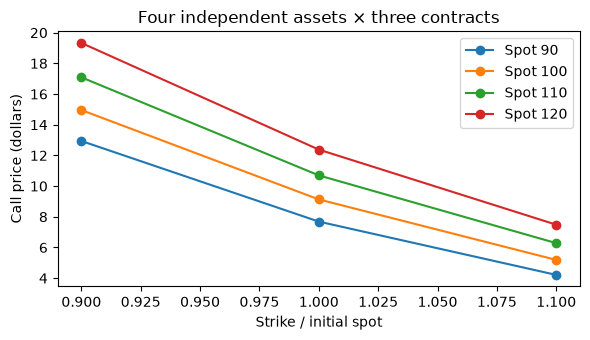

In [3]:
def measure(plan, device, repeats=3):
    evaluate(plan, device)  # warmup
    durations = []
    for _ in range(repeats):
        if device == "cuda": torch.cuda.synchronize()
        start = time.perf_counter()
        evaluate(plan, device)
        if device == "cuda": torch.cuda.synchronize()
        durations.append(time.perf_counter()-start)
    return statistics.median(durations)

timings = {"cpu": measure(cpu_plan, "cpu")}
if cuda_available:
    timings["cuda"] = measure(gpu_plan, "cuda")
for device, seconds in timings.items():
    print(f"{device}: median price + backward = {1000*seconds:.3f} ms (3 repetitions)")
fig, ax = plt.subplots(figsize=(6, 3.5))
for i, row in enumerate(cpu_prices.detach()):
    ax.plot([.9, 1., 1.1], row.tolist(), "o-", label=f"Spot {spots[i]:.0f}")
ax.set(xlabel="Strike / initial spot", ylabel="Call price (dollars)", title="Four independent assets × three contracts")
ax.legend()
fig.tight_layout()
plt.show()
RESULT = {"assets": len(spots), "contracts_per_asset": 3, "cuda_executed": cuda_available,
          "median_price_backward_seconds": timings, "prices": cpu_prices.detach().tolist(),
          "parameter_gradients": parameter_grad.tolist(), "spot_deltas": deltas.tolist()}

For throughput studies, enlarge both asset and contract axes and measure the
actual training objective, peak device memory and CPU thread count. Keep tensors
on the target device across optimizer iterations. Changing node/step counts
changes accuracy and cost together; a faster coarse solution is not an accuracy
comparison. See [the capability matrix](../docs/capabilities.md) for supported
exercise/dividend combinations and current CUDA restrictions.